# 📊 Notebook 1 — Exploración de Datos (EDA)

## ¿Qué es un EDA y por qué lo hacemos PRIMERO?

Antes de tocar modelos, necesitamos **entender los datos a fondo**. Sin EDA corremos el riesgo de entrenar un modelo con basura y no entender por qué falla.

El EDA (Exploratory Data Analysis) nos responde:
- ¿Cuántos datos tenemos y de qué tipo son?
- ¿Están balanceadas las clases? (igual número de spam y ham)
- ¿Hay valores faltantes? ¿Cuántos?
- ¿Cómo es la distribución del texto? ¿Mensajes cortos, largos?
- ¿Qué palabras aparecen más en spam vs. ham?

**Dataset:** 131,339 emails etiquetados de 5 fuentes académicas.
- `0` = HAM (email legítimo)
- `1` = PHISHING/SPAM (email malicioso)

---

## 1. Importar librerías

Cada librería tiene un propósito específico:
- **pandas**: Manipulación de datos en tablas (DataFrames)
- **numpy**: Operaciones matemáticas sobre arreglos
- **matplotlib / seaborn**: Visualización de datos
- **collections.Counter**: Contar frecuencias de palabras rápidamente

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
import os
import warnings

# Silenciar advertencias menores para que el output sea más limpio
warnings.filterwarnings('ignore')

# Configurar estilo de gráficas
# 'whitegrid' añade una cuadrícula blanca de fondo — facilita leer valores en los gráficos
sns.set_style('whitegrid')

# Tamaño de figura predeterminado para todas las gráficas
plt.rcParams['figure.figsize'] = (12, 5)

# Asegurarnos de que pandas muestra todas las columnas sin truncar
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)

print('✅ Librerías cargadas correctamente')

✅ Librerías cargadas correctamente


## 2. Cargar el Dataset

El archivo `merged_phishing_full.csv` es el resultado de unir 5 datasets académicos públicos:
| Dataset | Origen |
|---|---|
| Enron | Emails corporativos reales filtrados de la empresa Enron |
| LingSpam | Dataset clásico de investigación NLP |
| SpamAssassin | Usado por el filtro de spam de Apache |
| CEAS 2008 | Competencia académica de detección de spam |
| TREC 2007 | Track de detección de spam del NIST |

> **Nota sobre rutas:** Usamos una ruta relativa desde la carpeta `notebooks/`. El `..` sube un nivel al directorio raíz del proyecto.

In [2]:
# Definir ruta al dataset (relativa desde notebooks/)
DATA_PATH = '../data/processed/merged_phishing_full.csv'

# Leer el CSV con pandas
# El parámetro low_memory=False evita warnings cuando pandas no puede inferir
# el tipo de dato de una columna por ser mixta (strings y números)
df = pd.read_csv(DATA_PATH, low_memory=False)

print(f'Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Memoria usada: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB')

Dataset cargado: 131,339 filas × 8 columnas
Memoria usada: 290.9 MB


## 3. Inspección Básica

Primero vistazo a la estructura: tipos de datos, primeras filas y estadísticas básicas.

In [3]:
# .head() muestra las primeras 5 filas — primer contacto visual con los datos
print('=== PRIMERAS 5 FILAS ===')
df.head()

=== PRIMERAS 5 FILAS ===


,source,sender,receiver,date,subject,body,urls,label
0,Enron,NaN,NaN,NaN,"hpl nom for may 25 , 2001",( see attached file : hplno 525 . xls )\n- hplno 525 . xls,NaN,0
1,Enron,NaN,NaN,NaN,re : nom / actual vols for 24 th,- - - - - - - - - - - - - - - - - - - - - - forwarded by sabrae zajac / hou / ect on 05 / 30 / 2001 12 : 07 pm - - -...,NaN,0
2,Enron,NaN,NaN,NaN,"enron actuals for march 30 - april 1 , 201","estimated actuals\nmarch 30 , 2001\nno flow\nmarch 31 , 2001\nno flow\napril 1 , 2001\nteco tap 35 . 000\nwhen i rec...",NaN,0
3,Enron,NaN,NaN,NaN,"hpl nom for may 30 , 2001",( see attached file : hplno 530 . xls )\n- hplno 530 . xls,NaN,0
4,Enron,NaN,NaN,NaN,"hpl nom for june 1 , 2001",( see attached file : hplno 601 . xls )\n- hplno 601 . xls,NaN,0


In [4]:
# .info() es MUY útil: muestra tipo de dato de cada columna y cuántos valores no-nulos hay
# Si una columna tiene menos non-null que el total de filas → hay NaN ahí
print('=== INFORMACIÓN DEL DATAFRAME ===')
df.info()

=== INFORMACIÓN DEL DATAFRAME ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131339 entries, 0 to 131338
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   source    131339 non-null  object 
 1   sender    98720 non-null   object 
 2   receiver  97723 non-null   object 
 3   date      98697 non-null   object 
 4   subject   130586 non-null  object 
 5   body      131338 non-null  object 
 6   urls      98720 non-null   float64
 7   label     131339 non-null  int64  
dtypes: float64(1), int64(1), object(6)
memory usage: 8.0+ MB


In [5]:
# Ver las columnas disponibles
print('Columnas disponibles:')
for col in df.columns:
    dtype = df[col].dtype
    nulls = df[col].isna().sum()
    pct   = nulls / len(df) * 100
    print(f'  {col:<15} tipo={str(dtype):<10} nulos={nulls:>7,} ({pct:.1f}%)')

Columnas disponibles:
  source          tipo=object     nulos=      0 (0.0%)
  sender          tipo=object     nulos= 32,619 (24.8%)
  receiver        tipo=object     nulos= 33,616 (25.6%)
  date            tipo=object     nulos= 32,642 (24.9%)
  subject         tipo=object     nulos=    753 (0.6%)
  body            tipo=object     nulos=      1 (0.0%)
  urls            tipo=float64    nulos= 32,619 (24.8%)
  label           tipo=int64      nulos=      0 (0.0%)


## 4. Distribución de Clases

Esta es quizás la métrica más crítica del EDA para clasificación:
- Si hay **desequilibrio** (ej. 90% ham, 10% phishing), un modelo que siempre prediga 'ham' tendrá 90% de accuracy pero será inútil.
- En ese caso habría que usar técnicas como SMOTE, class_weight, o bajo-muestreo.

**Nuestro dataset fue diseñado para estar balanceado**, pero lo verificamos de todas formas.

In [6]:
# Contar cuántos emails hay de cada clase
class_counts = df['label'].value_counts().sort_index()

print('=== DISTRIBUCIÓN DE CLASES ===')
print(f"  HAM     (0): {class_counts[0]:>8,} ({class_counts[0]/len(df)*100:.1f}%)")
print(f"  PHISHING(1): {class_counts[1]:>8,} ({class_counts[1]/len(df)*100:.1f}%)")
print(f"  TOTAL      : {len(df):>8,}")

ratio = class_counts[1] / class_counts[0]
print(f"\n  Ratio phishing/ham: {ratio:.2f}  "
      f"({'BALANCEADO ✅' if 0.8 < ratio < 1.2 else 'DESBALANCEADO ⚠️'})")

=== DISTRIBUCIÓN DE CLASES ===
  HAM     (0):   63,949 (48.7%)
  PHISHING(1):   67,390 (51.3%)
  TOTAL      :  131,339

  Ratio phishing/ham: 1.05  (BALANCEADO ✅)


Gráfico guardado en reports/figures/


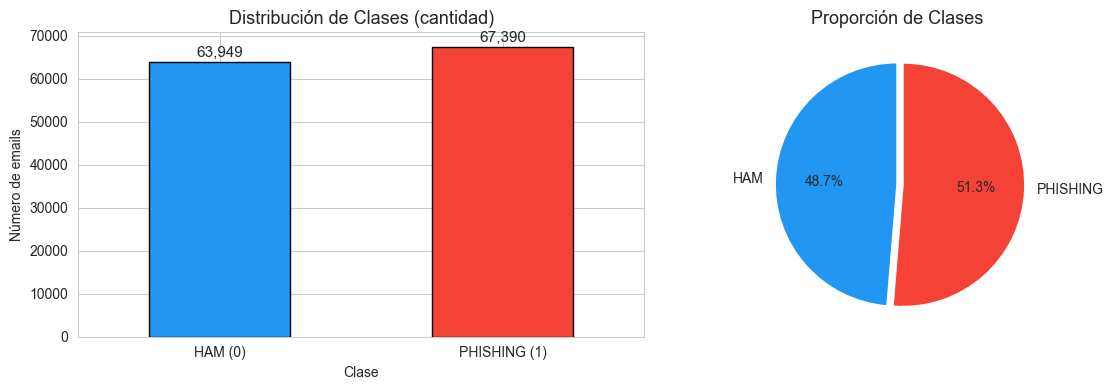

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico de barras — muestra cantidades absolutas
colors = ['#2196F3', '#F44336']  # azul=ham, rojo=phishing
class_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Distribución de Clases (cantidad)', fontsize=13)
axes[0].set_xlabel('Clase')
axes[0].set_ylabel('Número de emails')
axes[0].set_xticklabels(['HAM (0)', 'PHISHING (1)'], rotation=0)
# Añadir etiquetas de valor encima de cada barra
for bar, val in zip(axes[0].patches, class_counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'{val:,}', ha='center', va='bottom', fontsize=11)

# Gráfico de pie — muestra proporciones
axes[1].pie(class_counts, labels=['HAM', 'PHISHING'], autopct='%1.1f%%',
            colors=colors, startangle=90, explode=(0, 0.05))
axes[1].set_title('Proporción de Clases', fontsize=13)

plt.tight_layout()

# Guardar la figura en reports/
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/distribucion_clases.png', dpi=150, bbox_inches='tight')
print('Gráfico guardado en reports/figures/')
plt.show()

## 5. Distribución por Fuente

Cada dataset tiene su propio sesgo y características. Es importante saber cuánto contribuye cada fuente al total para entender si el modelo podría estar aprendiendo características del dataset en vez de del phishing en sí.

=== DISTRIBUCIÓN POR FUENTE ===
                HAM  PHISHING  TOTAL  %_PHISHING
source                                          
CEAS_08       17312     21842  39154        55.8
Enron         15791     13976  29767        47.0
LingSpam       2397       455   2852        16.0
SpamAssassin   4091      1718   5809        29.6
TREC_07       24358     29399  53757        54.7


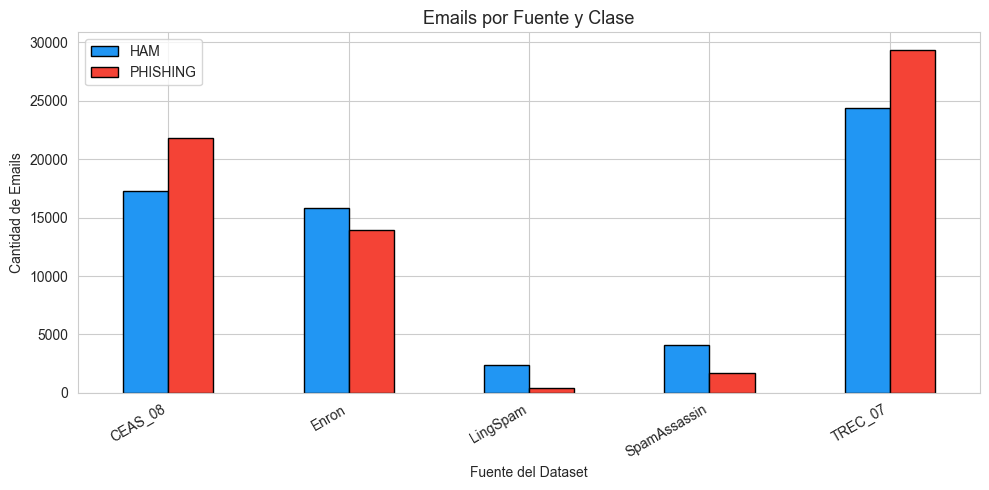

In [8]:
# Agrupar por fuente y clase para ver la distribución cruzada
if 'source' in df.columns:
    source_dist = df.groupby(['source', 'label']).size().unstack(fill_value=0)
    source_dist.columns = ['HAM', 'PHISHING']
    source_dist['TOTAL'] = source_dist.sum(axis=1)
    source_dist['%_PHISHING'] = (source_dist['PHISHING'] / source_dist['TOTAL'] * 100).round(1)
    
    print('=== DISTRIBUCIÓN POR FUENTE ===')
    print(source_dist.to_string())
    
    # Gráfico de barras apiladas
    fig, ax = plt.subplots(figsize=(10, 5))
    source_dist[['HAM', 'PHISHING']].plot(kind='bar', ax=ax, 
                                          color=['#2196F3', '#F44336'],
                                          edgecolor='black')
    ax.set_title('Emails por Fuente y Clase', fontsize=13)
    ax.set_xlabel('Fuente del Dataset')
    ax.set_ylabel('Cantidad de Emails')
    ax.legend(['HAM', 'PHISHING'])
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig('../reports/figures/distribucion_por_fuente.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Columna source no disponible')

## 6. Análisis de Valores Nulos

Los valores nulos son un problema real: si el modelo recibe un NaN donde espera texto, puede fallar o comportarse de forma inesperada.

**Estrategias posibles:**
- Rellenar con cadena vacía `''` (para texto)
- Eliminar filas con nulos en columnas críticas
- Rellenar con valor especial como `'[SIN_ASUNTO]'`

> Decidiremos la estrategia en el notebook de limpieza (Notebook 2).

=== COLUMNAS CON VALORES NULOS ===
          nulos  porcentaje
receiver  33616       25.59
date      32642       24.85
sender    32619       24.84
urls      32619       24.84
subject     753        0.57
body          1        0.00


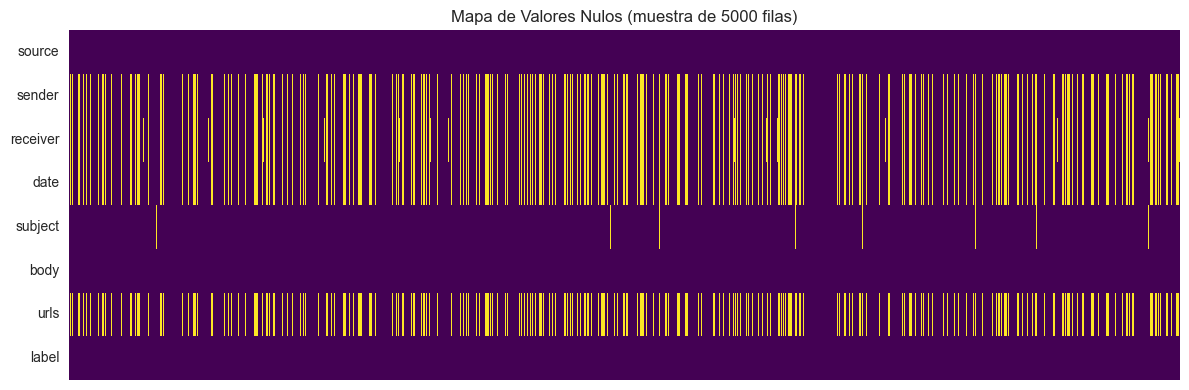

In [9]:
# Calcular nulos por columna
nulls = df.isnull().sum()
pcts  = (nulls / len(df) * 100).round(2)

null_df = pd.DataFrame({'nulos': nulls, 'porcentaje': pcts})
null_df = null_df[null_df['nulos'] > 0].sort_values('porcentaje', ascending=False)

if null_df.empty:
    print('✅ No hay valores nulos en ninguna columna.')
else:
    print('=== COLUMNAS CON VALORES NULOS ===')
    print(null_df.to_string())
    
    # Heatmap de nulos — visualiza dónde están los huecos en el dataset
    # Cada fila blanca en el heatmap representa un NaN
    fig, ax = plt.subplots(figsize=(12, 4))
    # Muestreamos 5000 filas para que el heatmap sea rápido de renderizar
    sample = df.isnull().sample(min(5000, len(df)), random_state=42)
    sns.heatmap(sample.T, cbar=False, yticklabels=True, xticklabels=False,
                cmap='viridis', ax=ax)
    ax.set_title('Mapa de Valores Nulos (muestra de 5000 filas)', fontsize=12)
    plt.tight_layout()
    plt.savefig('../reports/figures/mapa_nulos.png', dpi=150, bbox_inches='tight')
    plt.show()

## 7. Análisis de Longitud del Texto

Esta sección es **especialmente importante para BERT** (Notebook 4):
- BERT tiene un límite de **512 tokens** por defecto
- Necesitamos saber qué porcentaje de emails supera ese límite
- Si muchos emails son muy largos, habrá que decidir cómo truncarlos

También es útil para entender diferencias entre ham y phishing:
- Emails phishing tienden a ser más cortos y directos
- Emails legítimos suelen tener más contexto

In [10]:
# Calcular longitud en palabras de subject y body
# .fillna('') — reemplazar NaN con cadena vacía para que .split() no falle
# .str.split() — dividir por espacios en blanco
# .str.len() — contar el número de palabras

df_len = pd.DataFrame({
    'label'         : df['label'],
    'subject_words' : df['subject'].fillna('').astype(str).str.split().str.len(),
    'body_words'    : df['body'].fillna('').astype(str).str.split().str.len(),
})

# Calcular longitud total (subject + body)
df_len['total_words'] = df_len['subject_words'] + df_len['body_words']

print('=== ESTADÍSTICAS DE LONGITUD (palabras) ===')
stats = df_len.groupby('label')[['subject_words', 'body_words', 'total_words']].describe()
print(stats.to_string())

# ¿Qué porcentaje supera el límite de BERT (512 tokens ≈ ~384 palabras)?
# Asumimos ~1.33 tokens por palabra (promedio para texto en inglés)
TOKEN_LIMIT = 512
WORD_LIMIT  = int(TOKEN_LIMIT / 1.33)

pct_over = (df_len['total_words'] > WORD_LIMIT).mean() * 100
print(f"\n⚠️  Emails con más de ~{WORD_LIMIT} palabras (límite BERT): {pct_over:.1f}%")
print(f"   → Estos serán truncados durante el entrenamiento de BERT.")

=== ESTADÍSTICAS DE LONGITUD (palabras) ===
      subject_words                                                 body_words                                                           total_words                                                           
              count      mean       std  min  25%  50%  75%     max      count        mean         std  min   25%    50%    75%      max       count        mean         std  min    25%    50%    75%      max
label                                                                                                                                                                                                          
0           63949.0  6.642809  3.708129  0.0  4.0  6.0  8.0   162.0    63949.0  345.391562  804.093819  1.0  96.0  184.0  358.0  63374.0     63949.0  352.034371  804.142738  2.0  103.0  190.0  365.0  63380.0
1           67390.0  6.150883  7.848307  0.0  3.0  5.0  8.0  1665.0    67390.0  169.580131  320.774408  0.0  37.0   89.0  19

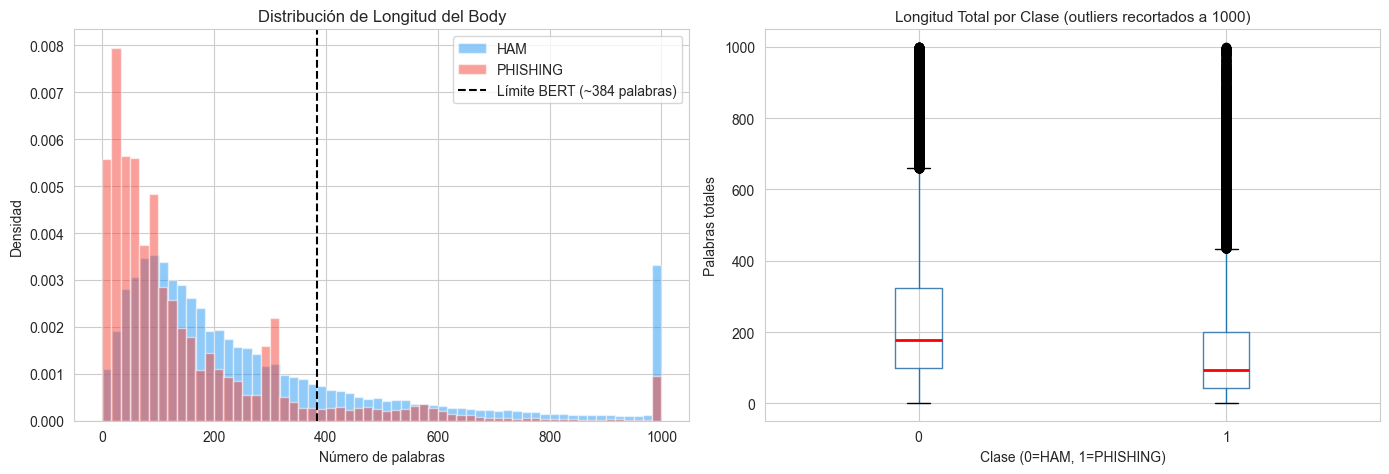

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de longitud del body separado por clase
# clip_upper limita valores extremos para que el histograma sea legible
for label, color, name in [(0, '#2196F3', 'HAM'), (1, '#F44336', 'PHISHING')]:
    subset = df_len[df_len['label'] == label]['body_words'].clip(upper=1000)
    # kde=True añade una curva de densidad suavizada encima del histograma
    axes[0].hist(subset, bins=60, alpha=0.5, color=color, label=name, density=True)

# Línea vertical en el límite de BERT
axes[0].axvline(WORD_LIMIT, color='black', linestyle='--', linewidth=1.5,
               label=f'Límite BERT (~{WORD_LIMIT} palabras)')
axes[0].set_title('Distribución de Longitud del Body', fontsize=12)
axes[0].set_xlabel('Número de palabras')
axes[0].set_ylabel('Densidad')
axes[0].legend()

# Boxplot para comparar medianas y percentiles entre clases
df_len[df_len['total_words'] < 1000].boxplot(
    column='total_words', by='label', ax=axes[1],
    boxprops=dict(color='steelblue'),
    medianprops=dict(color='red', linewidth=2)
)
axes[1].set_title('Longitud Total por Clase (outliers recortados a 1000)', fontsize=11)
axes[1].set_xlabel('Clase (0=HAM, 1=PHISHING)')
axes[1].set_ylabel('Palabras totales')
plt.suptitle('')  # Quitar el título automático de pandas

plt.tight_layout()
plt.savefig('../reports/figures/longitud_textos.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Palabras Más Frecuentes

Ver qué palabras son más comunes en cada clase nos da intuición sobre qué aprenderá el modelo. Si hay palabras que aparecen MUCHO más en phishing que en ham, son buenas señales de detección.

In [12]:
# Función para extraer las N palabras más frecuentes de una serie de texto
def top_words(series, n=30, stopwords=None):
    """
    series   : pd.Series de strings
    n        : cuántas palabras top devolver
    stopwords: set de palabras a ignorar (artículos, preposiciones, etc.)
    """
    if stopwords is None:
        # Stopwords básicas en inglés que no aportan información discriminativa
        stopwords = {'the','a','an','in','of','to','and','or','is','it','for',
                     'this','that','with','on','at','be','was','are','i','you',
                     'your','my','we','our','have','has','will','re','do','not',
                     'as','from','by','but','if','so','all','can','its','he','she'}
    
    # Unir todos los textos, limpiar caracteres no alfanuméricos, dividir en palabras
    all_words = ' '.join(series.fillna('').astype(str).str.lower())
    words = re.findall(r'\b[a-z]{3,}\b', all_words)  # solo palabras de 3+ letras
    
    # Filtrar stopwords
    words = [w for w in words if w not in stopwords]
    
    # Counter cuenta frecuencias y .most_common(n) devuelve las N más frecuentes
    return Counter(words).most_common(n)

print('Calculando frecuencias de palabras (puede tardar ~30 segundos)...')

# Tomar una muestra para que sea rápido — 20k emails por clase es representativo
sample_ham      = df[df['label']==0]['body'].sample(min(20000, (df['label']==0).sum()), random_state=42)
sample_phishing = df[df['label']==1]['body'].sample(min(20000, (df['label']==1).sum()), random_state=42)

top_ham      = top_words(sample_ham,      n=20)
top_phishing = top_words(sample_phishing, n=20)

print('\nTop 20 palabras en HAM:')
for word, count in top_ham:
    print(f'  {word:<20} {count:>6,}')

print('\nTop 20 palabras en PHISHING:')
for word, count in top_phishing:
    print(f'  {word:<20} {count:>6,}')

Calculando frecuencias de palabras (puede tardar ~30 segundos)...

Top 20 palabras en HAM:
  http                 36,536
  com                  30,120
  org                  24,386
  www                  18,047
  enron                17,411
  list                 14,561
  submission           14,165
  new                  12,635
  more                 12,575
  would                12,503
  help                 12,442
  please               12,053
  mail                 11,540
  ect                  11,216
  which                10,986
  one                  10,930
  there                10,926
  what                 10,685
  python               10,449
  message              10,304

Top 20 palabras en PHISHING:
  com                  40,115
  http                 34,626
  cnn                  33,372
  www                  24,414
  html                 20,449
  video                18,573
  index                18,241
  email                15,066
  partners              9,269
  url    

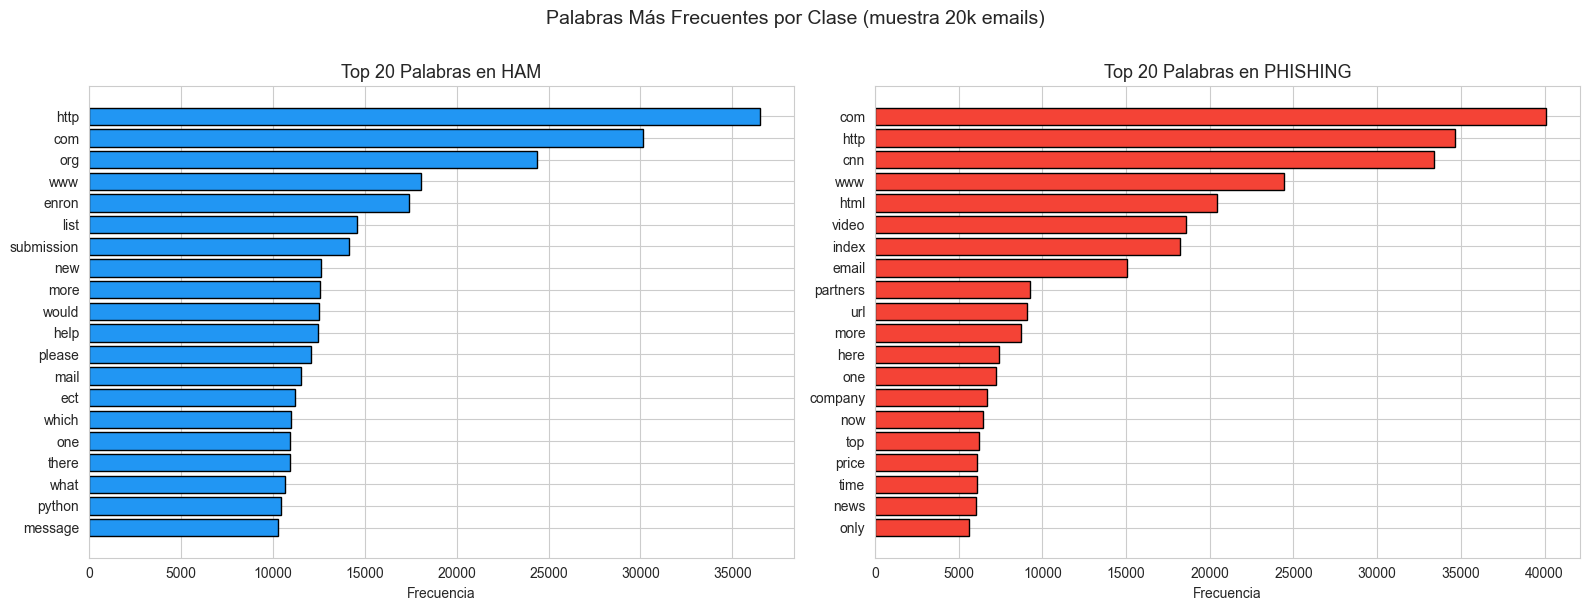

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Barras horizontales — más fáciles de leer cuando las etiquetas son palabras
words_ham, counts_ham           = zip(*top_ham)
words_phishing, counts_phishing = zip(*top_phishing)

axes[0].barh(words_ham[::-1], counts_ham[::-1], color='#2196F3', edgecolor='black')
axes[0].set_title('Top 20 Palabras en HAM', fontsize=13)
axes[0].set_xlabel('Frecuencia')

axes[1].barh(words_phishing[::-1], counts_phishing[::-1], color='#F44336', edgecolor='black')
axes[1].set_title('Top 20 Palabras en PHISHING', fontsize=13)
axes[1].set_xlabel('Frecuencia')

plt.suptitle('Palabras Más Frecuentes por Clase (muestra 20k emails)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/palabras_frecuentes.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Ejemplos Reales de Emails

Nada reemplaza ver los datos con tus propios ojos. Leer algunos ejemplos de cada clase ayuda a entender qué patrones existen.

In [15]:
def show_email_sample(df, label, n=3):
    """Muestra n emails de la clase especificada."""
    name = 'HAM' if label == 0 else 'PHISHING'
    print(f"\n{'='*60}")
    print(f"  EJEMPLOS DE {name}")
    print(f"{'='*60}")
    
    samples = df[df['label'] == label].sample(n, random_state=42)
    for i, (_, row) in enumerate(samples.iterrows(), 1):
        subj = str(row.get('subject', 'N/A'))[:100]
        body = str(row.get('body', 'N/A'))[:300]
        source = str(row.get('source', 'N/A'))
        print(f"\n--- Email #{i} (Fuente: {source}) ---")
        print(f"Asunto : {subj}")
        print(f"Cuerpo : {body}..." if len(str(row.get('body', ''))) > 300 else f"Cuerpo : {body}")
        print()

show_email_sample(df, label=0, n=3)  # 3 ejemplos de HAM
show_email_sample(df, label=1, n=3)  # 3 ejemplos de PHISHING


  EJEMPLOS DE HAM

--- Email #1 (Fuente: Enron) ---
Asunto : eastrans nomination change effective 2 / 3 / 01
Cuerpo : please increase deliveries to eastrans to 60 , 000 mmbtu / dy from 50 , 000
mmbtu / dy for 2 / 3 / 01 .
the redeliveries will be 7300 mmbtu / dy from fuels cotton valley and
52700 mmbtu / dy to pg & e


--- Email #2 (Fuente: CEAS_08) ---
Asunto : [SM-USERS] sendmail verbose output
Cuerpo : 

Hi,
My set up is
Debian - Etch / php5.2.08/apache2/squirrelmail1.5.1/plugins installed - calendar, squirrelspell, 'html_mail, spam_buttons.
For composing and sending mails through squirrelmail we use exim4 with additional -v argument for verbose output.
Some of our users want Delivery  Receipt, wh...


--- Email #3 (Fuente: SpamAssassin) ---
Asunto : Re: exmh bug?
Cuerpo : The way to debug something like this is to turn on the log (Preferences  -> Hacking Support -> Debug log enabled) and track the gpg commands  being issued and the responses. FWIW, using exmh 2.5 and gpg 1.0.7 I d

## 10. Conclusiones del EDA

Rellena esta celda después de ejecutar el notebook con tus observaciones:

### Lo que encontramos:
- **Clases:** El dataset está (aproximadamente) balanceado → No necesitamos técnicas de re-balanceo
- **Nulos:** Hay nulos principalmente en las columnas de ___ → Estrategia: rellenar con cadena vacía
- **Longitud:** El ___% de emails supera el límite de 512 tokens de BERT → Habrá truncamiento
- **Palabras spam:** Palabras como 'click', 'free', 'offer', 'account', 'verify' son mucho más comunes en phishing
- **Palabras ham:** Palabras más neutrales y específicas del contexto corporativo

### Decisiones para el Notebook 2 (Limpieza):
1. Rellenar NaN en `subject` y `body` con cadena vacía
2. Remover etiquetas HTML (emails HTML que quedaron con tags)
3. Normalizar URLs a token `[URL]`
4. Convertir todo a minúsculas
5. Guardar dataset limpio como `data/processed/phishing_clean.csv`

---
*Siguiente paso → [02_limpieza_preprocesamiento.ipynb](02_limpieza_preprocesamiento.ipynb)*